# Parte III - Análise estrutural

**Pré-requisito:** executar o notebook 01.

Small-world (Apêndice A) - **Sem bibliotecas prontas**: clusterização, BFS, caminho médio e gerador G(n,m) implementados aqui

Lei de potência (Apêndice B) - PDF e CCDF em log-log + ajuste por máxima verossimilhança (MLE) com k_min escolhido por KS + teste de aderência

Robustez (Apêndice C) - Remoção aleatória de 5 % (T = 30) x ataque por **grau** x ataque por **intermediação**

Comparação com ER, BA, WS - Modelos calibrados para o mesmo |V| e aproximadamente mesmo |E|, várias sementes

**Política para grafo desconexo (Apêndice C):** o Gnutella06 é conexo (1 WCC), todo o estudo não dirigido é feito na maior componente
(que é o grafo inteiro). A célula de carga verifica isso.

**Distância média:** calculada por **BFS própria** a partir de uma amostra de fontes, com IC 95 % (Normal Z)
sobre as médias por fonte.

In [1]:
import heapq, random
from collections import Counter, deque
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import zeta

# Semente fixa para reproduções futuras e valor crítico (aprox 1,96) da Normal para o IC de 95%
SEED = 42
Z_CRIT = stats.norm.ppf(0.975)

# Define os caminhos das pastas do projeto e cria os diretórios de saída
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
FIGURES_DIR = ROOT_DIR / "figures"
TABLES_DIR = ROOT_DIR / "results"
for d in (FIGURES_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# Carrega os grafos limpos (direcionado e não direcionado) gerados no notebook 01
G_dir = nx.read_edgelist(PROCESSED_DIR / "gnutella06_directed_clean.edgelist", create_using=nx.DiGraph, nodetype=int)
G_undir = nx.read_edgelist(PROCESSED_DIR / "gnutella06_undirected_clean.edgelist", create_using=nx.Graph, nodetype=int)

# Mapeia os IDs originais dos vértices para índices contínuos de 0 a N-1
nodes = sorted(G_undir.nodes())
idx = {v: i for i, v in enumerate(nodes)}
N = len(nodes)
M = G_undir.number_of_edges()
arestas = [(idx[u], idx[v]) for u, v in G_undir.edges()]

# Guarda a vizinhança em listas (ideal para percorrer na BFS) e em conjuntos (busca rápida na clusterização)
adj = [[] for _ in range(N)]
for u, v in arestas:
    adj[u].append(v); adj[v].append(u)
adj_set = [set(a) for a in adj]

# Confirma que a rede é conexa antes de prosseguir com as métricas
assert len(list(nx.connected_components(G_undir))) == 1, "grafo desconexo: aplicar a política do Apêndice C (maior componente)"
print(f"n = {N}, m = {M}, grau médio = {2 * M / N:.4f}")

# Quantidade de vértices sorteados como origem nas BFSs usadas para estimar o caminho médio
S_Q1, S_Q35 = 300, 200

n = 8717, m = 31525, grau médio = 7.2330


## Utilitários próprios (BFS, componentes, clusterização, G(n,m))

In [2]:
# BFS simples para calcular a distância em saltos a partir de s (-1 indica inalcançável).
def bfs_dist(adj, s):
    dist = [-1] * len(adj)
    dist[s] = 0
    fila = deque([s])
    while fila:
        u = fila.popleft()
        for v in adj[u]:
            if dist[v] < 0:
                dist[v] = dist[u] + 1
                fila.append(v)
    return dist


# Encontra as componentes conexas percorrendo apenas os vértices listados em vivos.
def componentes(adj, vivos):
    '''Componentes conexas (BFS) restritas à lista de vértices `vivos`.'''
    visto = set(); comps = []
    for r in vivos:
        if r in visto:
            continue
        comp = [r]; visto.add(r); fila = deque([r])
        while fila:
            u = fila.popleft()
            for v in adj[u]:
                if v not in visto:
                    visto.add(v); comp.append(v); fila.append(v)
        comps.append(comp)
    return comps


# Estima o caminho médio L a partir de uma amostra de origens e calcula o IC de 95% (Normal Z).
def caminho_medio_amostrado(adj, fontes):
    '''L = média, sobre as fontes, da distância média até os vértices alcançáveis. IC 95% (Normal Z) entre fontes.'''
    medias, ecc = [], 0
    for s in fontes:
        d = [x for x in bfs_dist(adj, s) if x > 0]
        medias.append(sum(d) / len(d))
        ecc = max(ecc, max(d))
    medias = np.array(medias)
    meia = Z_CRIT * medias.std(ddof=1) / np.sqrt(len(medias))
    return {"L": medias.mean(), "ic": meia, "ecc_max": ecc} # ecc_max serve de piso para o diâmetro


# Calcula a clusterização média C e o total de triângulos contando arestas entre vizinhos.
def clusterizacao_manual(adj_set):
    '''Clusterização média C (vértices com grau < 2 contam 0) e numero de triângulos, direto das listas de adjacência.'''
    coefs, soma_lig = [], 0
    for u, viz in enumerate(adj_set):
        k = len(viz)
        if k < 2:
            coefs.append(0.0); continue
        vl = list(viz); lig = 0
        for i in range(k):
            vi = adj_set[vl[i]]
            for j in range(i + 1, k):
                if vl[j] in vi:
                    lig += 1
        coefs.append(2.0 * lig / (k * (k - 1)))
        soma_lig += lig
    return float(np.mean(coefs)), soma_lig // 3 # divide por 3 pois cada triângulo aparece nos 3 nós


# Gera um grafo aleatório simples G(n, m) sorteando pares sem repetir arestas nem criar laços.
def gerar_gnm(n, m, seed):
    '''Grafo aleatório simples G(n, m) (ER): sorteia pares distintos até ter m arestas.'''
    rng = random.Random(seed)
    a = [set() for _ in range(n)]
    cont = 0
    while cont < m:
        u, v = rng.randrange(n), rng.randrange(n)
        if u != v and v not in a[u]:
            a[u].add(v); a[v].add(u); cont += 1
    return a


# Atalhos para extrair a maior componente e converter conjuntos de vizinhos em listas.
def maior_componente(adj):
    return max(componentes(adj, range(len(adj))), key=len)

def lista_de_conjuntos(adj_set_):
    return [list(s) for s in adj_set_]

# Valida as implementações próprias contra o NetworkX em um grafo pequeno de teste.
_T = nx.gnm_random_graph(200, 800, seed=1)
_aset = [set(_T.neighbors(i)) for i in range(200)]
_c, _t = clusterizacao_manual(_aset)
assert abs(_c - nx.average_clustering(_T)) < 1e-12 and _t == sum(nx.triangles(_T).values()) // 3
assert bfs_dist([list(s) for s in _aset], 0)[5] == nx.shortest_path_length(_T, 0, 5)
print("Utilitários próprios conferem com o NetworkX.")

Utilitários próprios conferem com o NetworkX.


## Propriedade small-world (Apêndice A)

In [3]:
rng_q1 = random.Random(SEED)

# Mede a clusterização exata e estima o caminho médio (via 300 BFS) no Gnutella06 real
C_real, tri_real = clusterizacao_manual(adj_set)
fontes = rng_q1.sample(range(N), S_Q1)
r_real = caminho_medio_amostrado(adj, fontes)

# Gera 10 grafos aleatórios G(n, m) com mesmo numero de vértices e arestas para servir de base nula
C_rand, L_rand, L_ic = [], [], []
for s in range(10):
    a = gerar_gnm(N, M, seed=100 + s)
    C_rand.append(clusterizacao_manual(a)[0])
    al = lista_de_conjuntos(a)
    lcc = maior_componente(al)
    f = random.Random(SEED + s).sample(lcc, S_Q1)
    r = caminho_medio_amostrado(al, f)
    L_rand.append(r["L"]); L_ic.append(r["ic"])

# Calcula as razões em relação ao grafo aleatório e o índice small-world (sigma)
C_r, L_r = np.mean(C_rand), np.mean(L_rand)
razao_C, razao_L = C_real / C_r, r_real["L"] / L_r
sigma = razao_C / razao_L

# Exibe a tabela comparativa, imprime os detalhes e exporta
tabela_q1 = pd.DataFrame([
    {"Grafo": "Gnutella06 (não dirigido)", "C": C_real, "L": r_real["L"], "IC95% de L (±)": r_real["ic"]},
    {"Grafo": "G(n,m) aleatório (média de 10)", "C": C_r, "L": L_r, "IC95% de L (±)": np.mean(L_ic)},
])
display(tabela_q1.round(5))
print(f"C(G)/C_rand = {razao_C:.2f} | L(G)/L_rand = {razao_L:.3f} | sigma = {sigma:.2f}")
print(f"C_rand: média {C_r:.6f}, dp {np.std(C_rand, ddof=1):.6f} | L_rand: média {L_r:.4f}, dp {np.std(L_rand, ddof=1):.4f}")
print(f"Gnutella06: C absoluto = {C_real:.4f} (valor baixo em termos absolutos) | triângulos = {tri_real}")
print("L exato (notebook 01, BFS de todas as fontes) deve ficar dentro de L ± IC acima.")

pd.DataFrame([{"C_real": C_real, "L_real": r_real["L"], "L_real_ic": r_real["ic"], "C_rand": C_r, "L_rand": L_r,
               "C_sobre_Crand": razao_C, "L_sobre_Lrand": razao_L, "sigma": sigma}]).to_csv(TABLES_DIR / "tabela_q1_smallworld.csv", index=False)

,Grafo,C,L,IC95% de L (±)
0,Gnutella06 (não dirigido),0.00668,4.53001,0.05192
1,"G(n,m) aleatório (média de 10)",0.00082,4.80317,0.02557


C(G)/C_rand = 8.17 | L(G)/L_rand = 0.943 | sigma = 8.67
C_rand: média 0.000817, dp 0.000149 | L_rand: média 4.8032, dp 0.0132
Gnutella06: C absoluto = 0.0067 (valor baixo em termos absolutos) | triângulos = 1142
L exato (notebook 01, BFS de todas as fontes) deve ficar dentro de L ± IC acima.


## Distribuição de graus e lei de potência (Apêndice B)

MLE: gamma = 4.618 | k_min = 11 (escolhido por KS) | pontos na cauda = 3060 (35.1%) | KS = 0.0320
Teste de aderência (bootstrap, B=100): p = 0.00  (p >= 0,1 -> lei de potência plausível; p < 0,1 -> rejeitada)
Diagnóstico OLS na CCDF (k >= k_min): gamma ≈ 3.784 | R² = 0.904
Grau máximo = 115 | grau médio = 7.233 | décadas de grau na cauda: 1.02


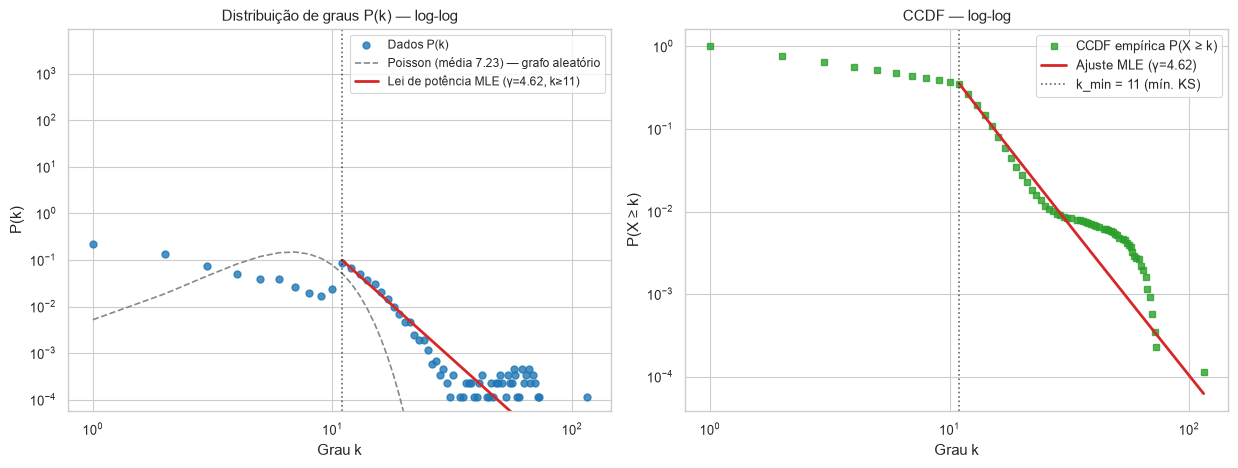

In [4]:
# Extrai o vetor de graus e calcula a distribuição P(k) e a acumulada complementar (CCDF)
graus = np.array([len(a) for a in adj])
n_g = len(graus)
cont = Counter(graus.tolist())
ks = np.array(sorted(cont)); pk = np.array([cont[k] for k in ks]) / n_g
ccdf = np.array([(graus >= k).sum() for k in ks]) / n_g


# Estima o expoente alpha (gama) por máxima verossimilhança discreta para k >= kmin
def mle_alpha(x, kmin):
    '''MLE discreto de alpha para x >= kmin (grade fina sobre a log-verossimilhança exata com zeta de Hurwitz).'''
    x = x[x >= kmin]; n = len(x)
    a0 = 1 + n / np.sum(np.log(x / (kmin - 0.5)))              # aproximação inicial contínua
    grade = np.linspace(max(1.01, a0 - 0.6), a0 + 0.6, 241)    # refina a busca em torno de a0
    ll = -grade * np.sum(np.log(x)) - n * np.log(zeta(grade, kmin))
    return float(grade[np.argmax(ll)])


# Mede a distância máxima (KS) entre a cauda empírica e a lei de potência ajustada
def ks_dist(x, kmin, alpha):
    x = np.sort(x[x >= kmin]); n = len(x)
    kk = np.unique(x)
    emp = (n - np.searchsorted(x, kk, side="left")) / n
    mod = zeta(alpha, kk) / zeta(alpha, kmin)
    return float(np.max(np.abs(emp - mod)))


# Testa vários cortes de kmin e escolhe o que minimiza o erro KS (exigindo ao menos 50 nós na cauda)
def melhor_ajuste(x, min_cauda=50):
    melhor = None
    for kmin in np.unique(x):
        if (x >= kmin).sum() < min_cauda:
            continue
        a = mle_alpha(x, kmin)
        d = ks_dist(x, kmin, a)
        if melhor is None or d < melhor[2]:
            melhor = (int(kmin), a, d)
    return melhor


# Teste de aderência via bootstrap: gera B amostras sintéticas e vê quantas têm KS >= KS observado
def gof_bootstrap(x, kmin, alpha, B, seed):
    '''p-valor: fração de amostras sintéticas (cauda = lei de potência ajustada, corpo = empírico) com KS >= KS observado.'''
    rng = np.random.default_rng(seed)
    n = len(x); corpo = x[x < kmin]; p_cauda = (x >= kmin).mean()
    K = np.arange(kmin, 20000)
    cdf = np.cumsum(K ** (-alpha)); cdf /= cdf[-1]
    ks_obs = ks_dist(x, kmin, alpha)
    maiores = 0
    for _ in range(B):
        # Mantém o corpo abaixo de kmin igual aos dados reais e sorteia a cauda pelo modelo ajustado
        eh_cauda = rng.random(n) < p_cauda if len(corpo) else np.ones(n, bool)
        s = np.where(eh_cauda, kmin + np.searchsorted(cdf, rng.random(n)),
                     rng.choice(corpo, n) if len(corpo) else 0)
        ajuste = melhor_ajuste(s)
        if ajuste is not None and ajuste[2] >= ks_obs:
            maiores += 1
    return maiores / B


# Roda o ajuste MLE, o bootstrap (B=100) e uma regressão linear na CCDF apenas como diagnóstico
kmin, alpha, ks_obs = melhor_ajuste(graus)
n_cauda = int((graus >= kmin).sum())
p_val = gof_bootstrap(graus, kmin, alpha, B=100, seed=SEED)

m_ = ks >= kmin
reg = stats.linregress(np.log10(ks[m_]), np.log10(ccdf[m_])) # inclinação da CCDF equivale a -(gama - 1)
print(f"MLE: gamma = {alpha:.3f} | k_min = {kmin} (escolhido por KS) | pontos na cauda = {n_cauda} ({100*n_cauda/n_g:.1f}%) | KS = {ks_obs:.4f}")
print(f"Teste de aderência (bootstrap, B=100): p = {p_val:.2f}  (p >= 0,1 -> lei de potência plausível; p < 0,1 -> rejeitada)")
print(f"Diagnóstico OLS na CCDF (k >= k_min): gamma ≈ {1 - reg.slope:.3f} | R² = {reg.rvalue**2:.3f}")
print(f"Grau máximo = {graus.max()} | grau médio = {graus.mean():.3f} | décadas de grau na cauda: {np.log10(graus.max() / kmin):.2f}")

# Salva os parâmetros encontrados em CSV para a tabela do relatório
pd.DataFrame([{"gamma_MLE": alpha, "k_min": kmin, "n_cauda": n_cauda, "KS": ks_obs, "p_valor_bootstrap": p_val,
               "gamma_OLS_CCDF": 1 - reg.slope, "R2_OLS_CCDF": reg.rvalue ** 2, "grau_max": int(graus.max())}]).to_csv(TABLES_DIR / "tabela_q2_powerlaw.csv", index=False)

# --- Figura: PDF e CCDF em escala log-log ---
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Painel esquerdo: P(k) empírico vs. Poisson (grafo aleatório) e curva da lei de potência
axes[0].loglog(ks, pk, "o", ms=5, alpha=0.8, color="#1f77b4", label="Dados P(k)")
axes[0].loglog(ks, stats.poisson.pmf(ks, graus.mean()), "--", color="#7f8c8d", label=f"Poisson (média {graus.mean():.2f}) — grafo aleatório")
kk = ks[ks >= kmin]
axes[0].loglog(kk, (n_cauda / n_g) * kk ** (-alpha) / zeta(alpha, kmin), "-", color="#d62728", lw=2, label=f"Lei de potência MLE (γ={alpha:.2f}, k≥{kmin})")
axes[0].axvline(kmin, color="black", ls=":", alpha=0.6)
axes[0].set_ylim(bottom=0.5 / n_g)
axes[0].set_title("Distribuição de graus P(k) — log-log"); axes[0].set_xlabel("Grau k"); axes[0].set_ylabel("P(k)"); axes[0].legend(fontsize=8.5)

# Painel direito: CCDF P(X >= k), que reduz o ruído visual na ponta da cauda
axes[1].loglog(ks, ccdf, "s", ms=4.5, alpha=0.8, color="#2ca02c", label="CCDF empírica P(X ≥ k)")
axes[1].loglog(kk, (n_cauda / n_g) * zeta(alpha, kk) / zeta(alpha, kmin), "-", color="#d62728", lw=2, label=f"Ajuste MLE (γ={alpha:.2f})")
axes[1].axvline(kmin, color="black", ls=":", alpha=0.6, label=f"k_min = {kmin} (mín. KS)")
axes[1].set_title("CCDF — log-log"); axes[1].set_xlabel("Grau k"); axes[1].set_ylabel("P(X ≥ k)"); axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "parte3_power_law.png", dpi=300, bbox_inches="tight")
plt.show()

## Robustez (Apêndice C)

n = 8717 | r = ceil(0,05 * n) = 436
Ataque por grau: grau do r-ésimo vértice = 17; vértices com esse grau = 129 (empate no corte, resolvido pelo índice)
Betweenness: igraph (exata)


,Cenário,A: S (abs.),A: S/n,A: S/(n−r),B: nº comp.,C: dist. média,C: diâm. (≥),D: frac. isolados
0,Original (intacta),8717,1.0000,—,1,4.5416,9,0.0000
1,"Aleatória 5% (média ± dp, T=30)",8177.7,0.9381 ± 0.0018,0.9875 ± 0.0019,103.3000 ± 15.4365,4.5935 ± 0.0199,9.2,0.0122 ± 0.0019
2,Ataque 5% — grau,7952,0.9122,0.9603,330,5.1462,10,0.0397
3,Ataque 5% — intermediação,7768,0.8911,0.9381,508,5.0748,9,0.0606


,Ataque,S_rand / S_cent,c_cent / c_rand (nº de componentes),iso_cent / iso_rand (fração de isolados),dist_cent / dist_rand
0,grau,1.028,3.195,3.249,1.120
1,intermediação,1.053,4.918,4.957,1.105



Sensibilidade ao desempate do ataque por grau (10 desempates aleatórios):


,S_n,n_comp,dist_media,frac_iso
mean,0.9120,332.1000,5.1437,0.0400
std,0.0007,6.3675,0.0228,0.0008


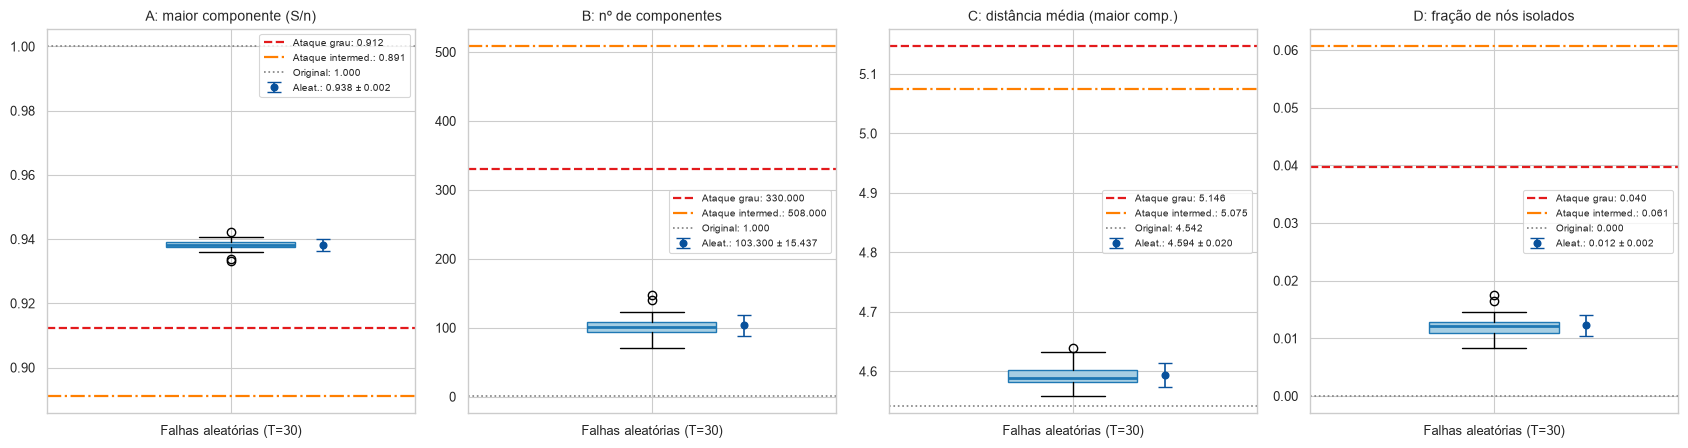

In [5]:
# Define r como 5% do total de vértices (arredondado para cima)
r = int(np.ceil(0.05 * N))
print(f"n = {N} | r = ceil(0,05 * n) = {r}")


# Remove os vértices indicados e calcula as quatro métricas de robustez (A, B, C e D) na rede restante.
def avaliar(removidos, n_fontes=S_Q35, seed=SEED):
    morto = np.zeros(N, dtype=bool)
    morto[list(removidos)] = True
    vivos = [u for u in range(N) if not morto[u]]
    # Monta a nova lista de adjacência mantendo apenas conexões entre nós sobreviventes
    adj_r = [[v for v in adj[u] if not morto[v]] if not morto[u] else [] for u in range(N)]
    comps = componentes(adj_r, vivos)
    lcc = max(comps, key=len) # maior componente conexa restante
    iso = sum(1 for u in vivos if not adj_r[u]) # nós sobreviventes que ficaram isolados (grau 0)
    fontes = random.Random(seed).sample(lcc, min(n_fontes, len(lcc)))
    c = caminho_medio_amostrado(adj_r, fontes)
    return {"S_abs": len(lcc), "S_n": len(lcc) / N, "S_restante": len(lcc) / len(vivos), "n_comp": len(comps),
            "dist_media": c["L"], "diam_lb": c["ecc_max"], "frac_iso": iso / len(vivos)}


# Implementação própria de Brandes com k pivôs (usada apenas como plano B se o igraph não existir).
def betweenness_brandes_amostrado(adj, k, seed):
    '''Brandes com k pivôs (usado só se igraph não estiver instalado).'''
    n = len(adj); cb = [0.0] * n
    for s in random.Random(seed).sample(range(n), k):
        S = []; P = [[] for _ in range(n)]; sigma = [0] * n; sigma[s] = 1
        d = [-1] * n; d[s] = 0; fila = deque([s])
        while fila:
            v = fila.popleft(); S.append(v)
            for w in adj[v]:
                if d[w] < 0:
                    d[w] = d[v] + 1; fila.append(w)
                if d[w] == d[v] + 1:
                    sigma[w] += sigma[v]; P[w].append(v)
        delta = [0.0] * n
        while S:
            w = S.pop()
            for v in P[w]:
                delta[v] += sigma[v] / sigma[w] * (1 + delta[w])
            if w != s:
                cb[w] += delta[w]
    return cb


# --- (a) Remoção aleatória (falhas), T = 30 ---
# Sorteia r vértices ao acaso 30 vezes para medir o comportamento médio da rede sob falhas comuns
T_REPS = 30
rng_rob = random.Random(SEED)
aleat = pd.DataFrame([avaliar(rng_rob.sample(range(N), r)) for _ in range(T_REPS)])

# --- (b) Ataque por grau (ranking fixo; desempate pelo índice) ---
# Ordena do maior para o menor grau e remove os r hubs mais conectados
grau_v = [len(a) for a in adj]
rank_grau = sorted(range(N), key=lambda u: (-grau_v[u], u))
res_grau = avaliar(rank_grau[:r])
corte = grau_v[rank_grau[r - 1]]
print(f"Ataque por grau: grau do r-ésimo vértice = {corte}; vértices com esse grau = {sum(1 for g in grau_v if g == corte)} "
      f"(empate no corte, resolvido pelo índice)")

# Análise de sensibilidade: repete o ataque com 10 desempates aleatórios para confirmar que o índice não enviesa o resultado
sens = []
for s in range(10):
    rr = random.Random(1000 + s)
    rk = sorted(range(N), key=lambda u: (-grau_v[u], rr.random()))
    sens.append(avaliar(rk[:r]))
sens = pd.DataFrame(sens)

# --- (c) Ataque por intermediação (betweenness) ---
# Calcula a centralidade de intermediação exata pelo igraph (ou Brandes amostrado) e remove os top r nós ponte
try:
    import igraph as ig
    btw = ig.Graph(n=N, edges=arestas, directed=False).betweenness(directed=False)
    BTW_METODO = "igraph (exata)"
except ImportError:
    btw = betweenness_brandes_amostrado(adj, k=500, seed=SEED)
    BTW_METODO = "Brandes próprio com 500 pivôs (aproximada)"
print("Betweenness:", BTW_METODO)
rank_btw = sorted(range(N), key=lambda u: (-btw[u], u))
res_btw = avaliar(rank_btw[:r])

# --- Rede original (linha de base calculada diretamente) ---
orig = avaliar([])

def ms(col):
    return f"{aleat[col].mean():.4f} ± {aleat[col].std(ddof=1):.4f}"

# Consolida todos os cenários na tabela comparativa e salva
tabela_rob = pd.DataFrame([
    {"Cenário": "Original (intacta)", "A: S (abs.)": orig["S_abs"], "A: S/n": f"{orig['S_n']:.4f}", "A: S/(n−r)": "—",
     "B: nº comp.": orig["n_comp"], "C: dist. média": f"{orig['dist_media']:.4f}", "C: diâm. (≥)": orig["diam_lb"], "D: frac. isolados": f"{orig['frac_iso']:.4f}"},
    {"Cenário": f"Aleatória 5% (média ± dp, T={T_REPS})", "A: S (abs.)": f"{aleat['S_abs'].mean():.1f}", "A: S/n": ms("S_n"), "A: S/(n−r)": ms("S_restante"),
     "B: nº comp.": ms("n_comp"), "C: dist. média": ms("dist_media"), "C: diâm. (≥)": f"{aleat['diam_lb'].mean():.1f}", "D: frac. isolados": ms("frac_iso")},
    {"Cenário": "Ataque 5% — grau", "A: S (abs.)": res_grau["S_abs"], "A: S/n": f"{res_grau['S_n']:.4f}", "A: S/(n−r)": f"{res_grau['S_restante']:.4f}",
     "B: nº comp.": res_grau["n_comp"], "C: dist. média": f"{res_grau['dist_media']:.4f}", "C: diâm. (≥)": res_grau["diam_lb"], "D: frac. isolados": f"{res_grau['frac_iso']:.4f}"},
    {"Cenário": "Ataque 5% — intermediação", "A: S (abs.)": res_btw["S_abs"], "A: S/n": f"{res_btw['S_n']:.4f}", "A: S/(n−r)": f"{res_btw['S_restante']:.4f}",
     "B: nº comp.": res_btw["n_comp"], "C: dist. média": f"{res_btw['dist_media']:.4f}", "C: diâm. (≥)": res_btw["diam_lb"], "D: frac. isolados": f"{res_btw['frac_iso']:.4f}"},
])
display(tabela_rob)
tabela_rob.to_csv(TABLES_DIR / "tabela_q3_robustez.csv", index=False)

# Calcula as razões entre falhas aleatórias e ataques direcionados (S_rand/S_cent e c_cent/c_rand)
comp = pd.DataFrame([
    {"Ataque": nome,
     "S_rand / S_cent": aleat["S_n"].mean() / res["S_n"],
     "c_cent / c_rand (nº de componentes)": res["n_comp"] / aleat["n_comp"].mean(),
     "iso_cent / iso_rand (fração de isolados)": res["frac_iso"] / aleat["frac_iso"].mean(),
     "dist_cent / dist_rand": res["dist_media"] / aleat["dist_media"].mean()}
    for nome, res in [("grau", res_grau), ("intermediação", res_btw)]])
display(comp.round(3))
comp.to_csv(TABLES_DIR / "tabela_q3_razoes.csv", index=False)

print("\nSensibilidade ao desempate do ataque por grau (10 desempates aleatórios):")
display(sens[["S_n", "n_comp", "dist_media", "frac_iso"]].agg(["mean", "std"]).round(4))

# --- Figura: boxplots das 30 repetições aleatórias com linhas horizontais para os ataques ---
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
specs = [("S_n", "A: maior componente (S/n)"), ("n_comp", "B: nº de componentes"),
         ("dist_media", "C: distância média (maior comp.)"), ("frac_iso", "D: fração de nós isolados")]
for ax, (col, titulo) in zip(axes, specs):
    v = aleat[col]
    ax.boxplot(v, widths=0.35, patch_artist=True, boxprops=dict(facecolor="#a6cee3", edgecolor="#1f78b4"),
               medianprops=dict(color="#1f78b4", linewidth=2))
    ax.errorbar(1.25, v.mean(), yerr=v.std(ddof=1), fmt="o", color="#08519c", capsize=5, label=f"Aleat.: {v.mean():.3f} ± {v.std(ddof=1):.3f}")
    ax.axhline(res_grau[col], color="#e31a1c", ls="--", lw=1.6, label=f"Ataque grau: {res_grau[col]:.3f}")
    ax.axhline(res_btw[col], color="#ff7f00", ls="-.", lw=1.6, label=f"Ataque intermed.: {res_btw[col]:.3f}")
    ax.axhline(orig[col], color="gray", ls=":", lw=1.2, label=f"Original: {orig[col]:.3f}")
    ax.set_title(titulo, fontsize=10); ax.set_xticks([1]); ax.set_xticklabels([f"Falhas aleatórias (T={T_REPS})"])
    ax.legend(fontsize=7.5, loc="best")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "parte3_robustez_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

## Testes no Grafo, para análise e descobertas

In [6]:
# --- Descoberta final: o grafo muda muito se respeitarmos as direções ---

def alcance(adj_lista, origens):
    '''BFS a partir de vários vértices: devolve todos os vértices alcançáveis.'''
    visto = set(origens); fila = deque(origens)
    while fila:
        u = fila.popleft()
        for v in adj_lista[u]:
            if v not in visto:
                visto.add(v); fila.append(v)
    return visto

# 1) Reciprocidade: quantas arestas u -> v têm também a volta v -> u
n_dir = G_dir.number_of_edges()
n_rec = sum(1 for u, v in G_dir.edges() if G_dir.has_edge(v, u))

# 2) Estrutura "gravata-borboleta" (bow-tie) em torno da maior componente fortemente conexa (SCC)
nodes_d = sorted(G_dir.nodes()); idx_d = {v: i for i, v in enumerate(nodes_d)}
adj_out = [[] for _ in nodes_d]; adj_in = [[] for _ in nodes_d]
for u, v in G_dir.edges():
    adj_out[idx_d[u]].append(idx_d[v]); adj_in[idx_d[v]].append(idx_d[u])

sccs = list(nx.strongly_connected_components(G_dir))
nucleo = {idx_d[v] for v in max(sccs, key=len)}
frente = alcance(adj_out, list(nucleo)) # alcançados a partir do núcleo
tras = alcance(adj_in, list(nucleo)) # vértices que chegam ao núcleo
OUT = frente - nucleo
IN = tras - nucleo
OUTROS = set(range(len(nodes_d))) - frente - tras

# 3) Concentração nos hubs e assortatividade de grau (grafo não dirigido)
grau_ord = np.sort(graus)[::-1]
top1 = grau_ord[: round(0.01 * N)].sum() / grau_ord.sum()
top5 = grau_ord[: int(np.ceil(0.05 * N))].sum() / grau_ord.sum()
assort = nx.degree_assortativity_coefficient(G_undir)

descobertas = pd.DataFrame([
    {"Item": "Reciprocidade", "Resultado": f"{n_rec} de {n_dir} arestas têm reversa ({100*n_rec/n_dir:.2f}%)"},
    {"Item": "Componentes fortemente conexas", "Resultado": f"{len(sccs)} no total; a maior tem {len(nucleo)} vértices ({100*len(nucleo)/N:.1f}%)"},
    {"Item": "Bow-tie", "Resultado": f"núcleo={len(nucleo)} | IN={len(IN)} | OUT={len(OUT)} | outros={len(OUTROS)}"},
    {"Item": "Concentração nos hubs", "Resultado": f"top 1% = {100*top1:.1f}% da soma dos graus; top 5% = {100*top5:.1f}%"},
    {"Item": "Assortatividade de grau", "Resultado": f"{assort:.4f} (perto de 0: hubs não preferem se ligar a hubs nem a vértices pequenos)"},
])
pd.set_option("display.max_colwidth", 200)
display(descobertas)
descobertas.to_csv(TABLES_DIR / "tabela_q4_descobertas.csv", index=False)

,Item,Resultado
0,Reciprocidade,0 de 31525 arestas têm reversa (0.00%)
1,Componentes fortemente conexas,5492 no total; a maior tem 3226 vértices (37.0%)
2,Bow-tie,núcleo=3226 | IN=100 | OUT=5296 | outros=95
3,Concentração nos hubs,top 1% = 6.8% da soma dos graus; top 5% = 17.7%
4,Assortatividade de grau,0.0516 (perto de 0: hubs não preferem se ligar a hubs nem a vértices pequenos)


## O grafo se aproxima de ER, BA ou WS?

,Modelo,Arestas,Grau médio,Grau máx.,Clusterização C,Caminho médio L,Diâmetro (≥),Triângulos,KS grau vs real
0,Gnutella06 (real),31525,7.2330,115,0.0067,4.5416,9,1142,0.0000
1,ER,31525.0 ± 0.0,7.2330 ± 0.0000,19.6 ± 1.3,0.0009 ± 0.0001,4.7973 ± 0.0074,8.4 ± 0.5,67.8 ± 4.9,0.3647 ± 0.0031
2,BA (duplo),31529.2 ± 66.1,7.2340 ± 0.0152,282.0 ± 52.0,0.0065 ± 0.0004,3.9840 ± 0.0181,6.2 ± 0.4,848.8 ± 52.6,0.3599 ± 0.0000
3,WS (p=0.01),34868.0 ± 0.0,8.0000 ± 0.0000,10.0 ± 0.0,0.6237 ± 0.0009,16.8815 ± 0.2994,35.4 ± 1.1,50685.0 ± 68.8,0.5613 ± 0.0002
4,WS (p=0.1),34868.0 ± 0.0,8.0000 ± 0.0000,12.2 ± 0.4,0.4738 ± 0.0026,6.9190 ± 0.0116,11.0 ± 0.0,38166.2 ± 189.9,0.5262 ± 0.0026
5,WS (p=1.0),34868.0 ± 0.0,8.0000 ± 0.0000,17.6 ± 0.9,0.0008 ± 0.0001,4.6462 ± 0.0049,7.0 ± 0.0,70.4 ± 8.2,0.4633 ± 0.0023


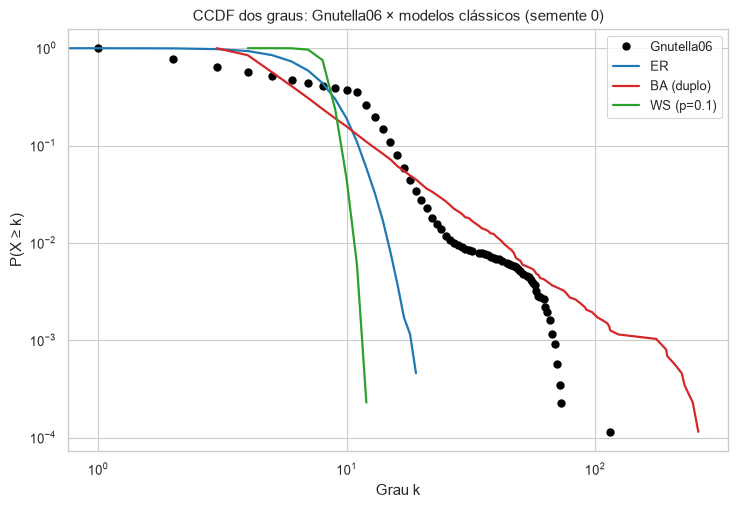

In [7]:
# Sementes para tirar média dos modelos e probabilidade p do BA duplo (calibra o numero de arestas)
SEEDS_MOD = [0, 1, 2, 3, 4]
p_ba = 4 - M / N

# Gera cada modelo sintético com N vértices e densidade calibrada para o Gnutella06
def gerar(modelo, s):
    if modelo == "ER":            return nx.gnm_random_graph(N, M, seed=s)
    if modelo == "BA (duplo)":    return nx.dual_barabasi_albert_graph(N, 3, 4, p_ba, seed=s)
    if modelo.startswith("WS"):   return nx.watts_strogatz_graph(N, 8, float(modelo.split("p=")[1].rstrip(")")), seed=s)

# Calcula as métricas estruturais do grafo gerado usando nossas funções próprias e o teste KS dos graus
def metricas_modelo(Gm, seed):
    a_list = [[] for _ in range(N)]; a_set = [set() for _ in range(N)]
    mapa = {v: i for i, v in enumerate(sorted(Gm.nodes()))}
    for u, v in Gm.edges():
        a_list[mapa[u]].append(mapa[v]); a_list[mapa[v]].append(mapa[u])
        a_set[mapa[u]].add(mapa[v]); a_set[mapa[v]].add(mapa[u])
    lcc = max(componentes(a_list, range(N)), key=len)
    c = caminho_medio_amostrado(a_list, random.Random(seed).sample(lcc, S_Q35))
    C, tri = clusterizacao_manual(a_set)
    gr = np.array([len(x) for x in a_list])
    return {"Arestas": Gm.number_of_edges(), "Grau médio": gr.mean(), "Grau máx.": gr.max(), "Clusterização C": C,
            "Caminho médio L": c["L"], "Diâmetro (≥)": c["ecc_max"], "Triângulos": tri,
            "KS grau vs real": stats.ks_2samp(graus, gr).statistic}, gr

linhas_mod, graus_exemplo = [], {}
# Mede primeiro a rede real para servir de linha de base
mr, _ = metricas_modelo(G_undir, SEED)
linhas_mod.append({"Modelo": "Gnutella06 (real)", **{k: f"{v:.4f}" if isinstance(v, float) else v for k, v in mr.items()}})

# Roda cada modelo nas 5 sementes, resume em média +- dp e guarda a semente 0 para o gráfico
for modelo in ["ER", "BA (duplo)", "WS (p=0.01)", "WS (p=0.1)", "WS (p=1.0)"]:
    regs = []
    for s in SEEDS_MOD:
        met, gr = metricas_modelo(gerar(modelo, s), s)
        regs.append(met)
        if s == 0: graus_exemplo[modelo] = gr
    df = pd.DataFrame(regs)
    linhas_mod.append({"Modelo": modelo, **{c: f"{df[c].mean():.4f} ± {df[c].std(ddof=1):.4f}" if c not in ("Arestas", "Grau máx.", "Triângulos", "Diâmetro (≥)")
                                            else f"{df[c].mean():.1f} ± {df[c].std(ddof=1):.1f}" for c in df.columns}})

# Monta a tabela comparativa final e exporta
df_modelos = pd.DataFrame(linhas_mod)
display(df_modelos)
df_modelos.to_csv(TABLES_DIR / "tabela_q5_modelos.csv", index=False)

# Plota a CCDF dos graus comparando o Gnutella06 real com os três modelos clássicos
plt.figure(figsize=(7.5, 5.2))
def ccdf_plot(gr, rotulo, **kw):
    kk = np.unique(gr); plt.loglog(kk, [(gr >= k).mean() for k in kk], **kw, label=rotulo)
ccdf_plot(graus, "Gnutella06", marker="o", ls="", ms=5, color="black")
for modelo, cor in [("ER", "#1f77b4"), ("BA (duplo)", "#d62728"), ("WS (p=0.1)", "#2ca02c")]:
    ccdf_plot(graus_exemplo[modelo], modelo, ls="-", lw=1.6, color=cor)
plt.xlabel("Grau k"); plt.ylabel("P(X ≥ k)"); plt.title("CCDF dos graus: Gnutella06 × modelos clássicos (semente 0)")
plt.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / "parte3_q5_ccdf_modelos.png", dpi=300, bbox_inches="tight")
plt.show()